In [105]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

In [106]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [107]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR + 'Data/processed/activity_recognition_data_WATCH_PHONE_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [108]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600,252207666810782,-0.36476135,8.793503,1.05508420,252207918580802,-0.85321045,0.297225950,0.89018250
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802,252207717164786,-0.87973020,9.768784,1.01699830,252207968934806,-0.87513730,0.015472412,0.16223145
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300,252207767518790,2.00149540,11.109070,2.61915600,252208019288809,-0.72016907,0.388488770,-0.28401184
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500,252207817872794,0.45062256,12.651642,0.18455505,252208069642813,-0.57164000,1.227401700,-0.24166870
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904,252207868226798,-2.16435240,13.928436,-4.42248540,252208119996817,-0.38049316,1.202835100,-0.21313477


In [109]:
data.isnull().sum()

pessoa_x                    0
atividade                   0
tempo_acelerômetro_watch    0
acelerômetro_x_watch        0
acelerômetro_Y_watch        0
acelerômetro_Z_watch        0
tempo_gyro_watch            0
giroscópio_x_watch          0
giroscópio_Y_watch          0
giroscópio_Z_watch          0
tempo_acelerômetro_phone    0
acelerômetro_x_phone        0
acelerômetro_Y_phone        0
acelerômetro_Z_phone        0
tempo_giroscópio_phone      0
giroscópio_x_phone          0
giroscópio_Y_phone          0
giroscópio_Z_phone          0
dtype: int64

In [110]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600,252207666810782,-0.36476135,8.793503,1.05508420,252207918580802,-0.85321045,0.297225950,0.89018250
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802,252207717164786,-0.87973020,9.768784,1.01699830,252207968934806,-0.87513730,0.015472412,0.16223145
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300,252207767518790,2.00149540,11.109070,2.61915600,252208019288809,-0.72016907,0.388488770,-0.28401184
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500,252207817872794,0.45062256,12.651642,0.18455505,252208069642813,-0.57164000,1.227401700,-0.24166870
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904,252207868226798,-2.16435240,13.928436,-4.42248540,252208119996817,-0.38049316,1.202835100,-0.21313477


In [111]:
data.columns

Index(['pessoa_x', 'atividade', 'tempo_acelerômetro_watch',
       'acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
       'tempo_gyro_watch', 'giroscópio_x_watch', 'giroscópio_Y_watch',
       'giroscópio_Z_watch', 'tempo_acelerômetro_phone',
       'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone',
       'tempo_giroscópio_phone', 'giroscópio_x_phone', 'giroscópio_Y_phone',
       'giroscópio_Z_phone'],
      dtype='object')

In [112]:
#remove the null class
data=data.dropna()

In [113]:
#data['root_sum_square_acel_xy'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Y']].pow(2).sum(axis=1))

In [114]:
#data['root_sum_square_acel_xz'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [115]:
#data['root_sum_square_acel_yz'] = np.sqrt(data[['acelerômetro_Y', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [116]:
#data['root_sum_square_giro_xy'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Y']].pow(2).sum(axis=1))

In [117]:
#data['root_sum_square_giro_xz'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Z']].pow(2).sum(axis=1))

In [118]:
#ata['root_sum_square_giro_yz'] = np.sqrt(data[['giroscópio_Y', 'giroscópio_Z']].pow(2).sum(axis=1))

In [119]:
grouped_data = pd.DataFrame(data.groupby(['pessoa_x', 'atividade'])['tempo_acelerômetro_watch'].count())

# **Data Exploration**

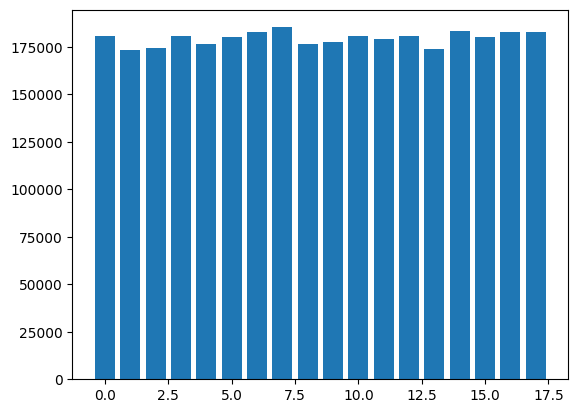

In [120]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

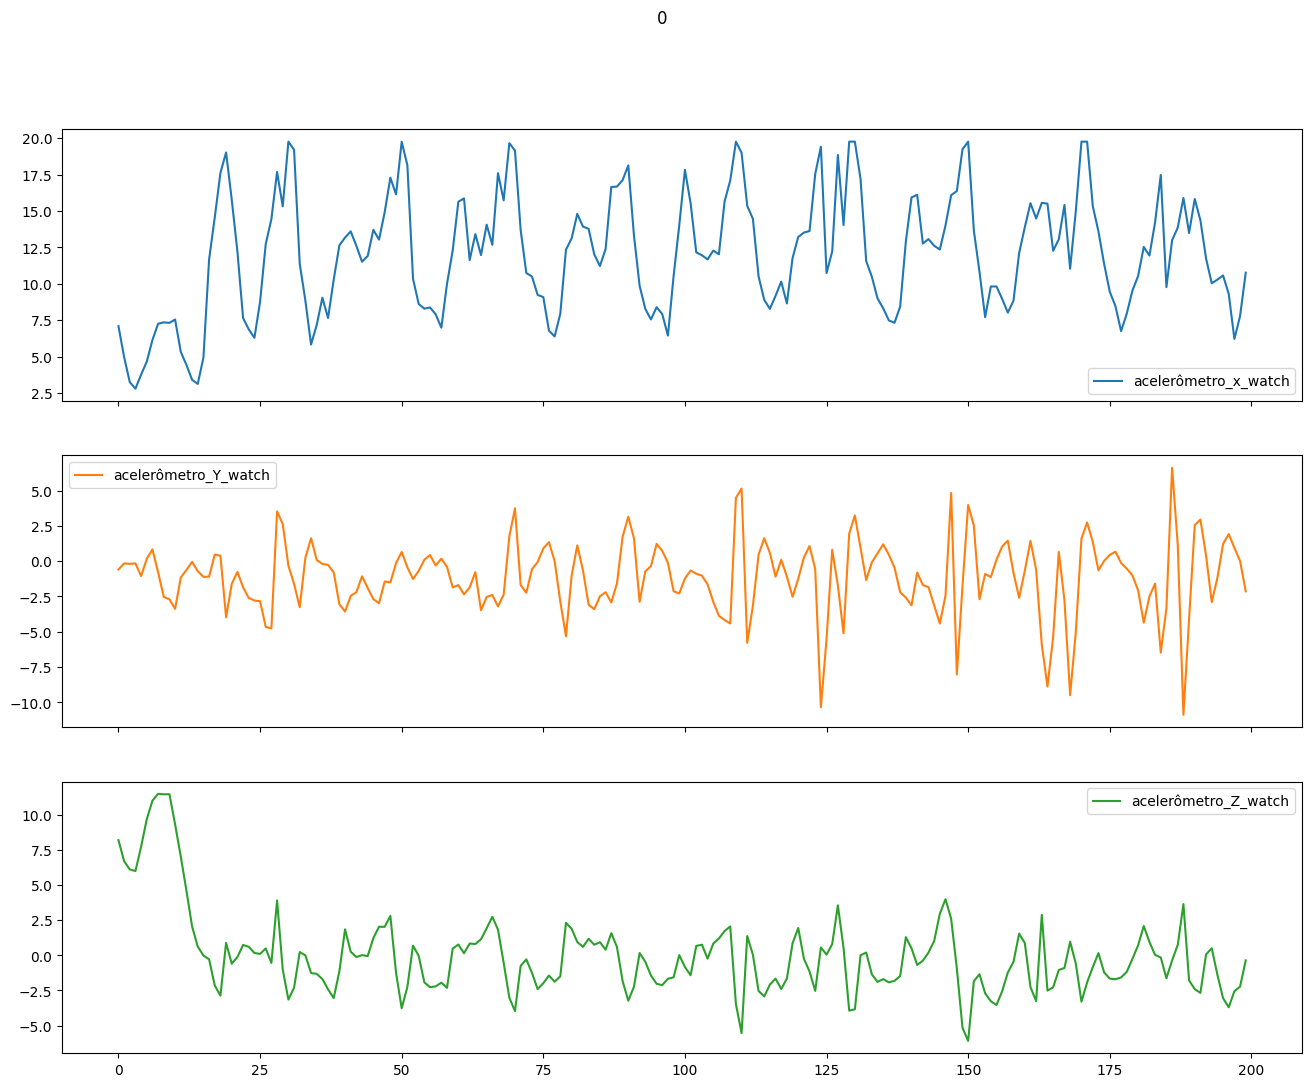

In [121]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x_watch','acelerômetro_Y_watch','acelerômetro_Z_watch']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

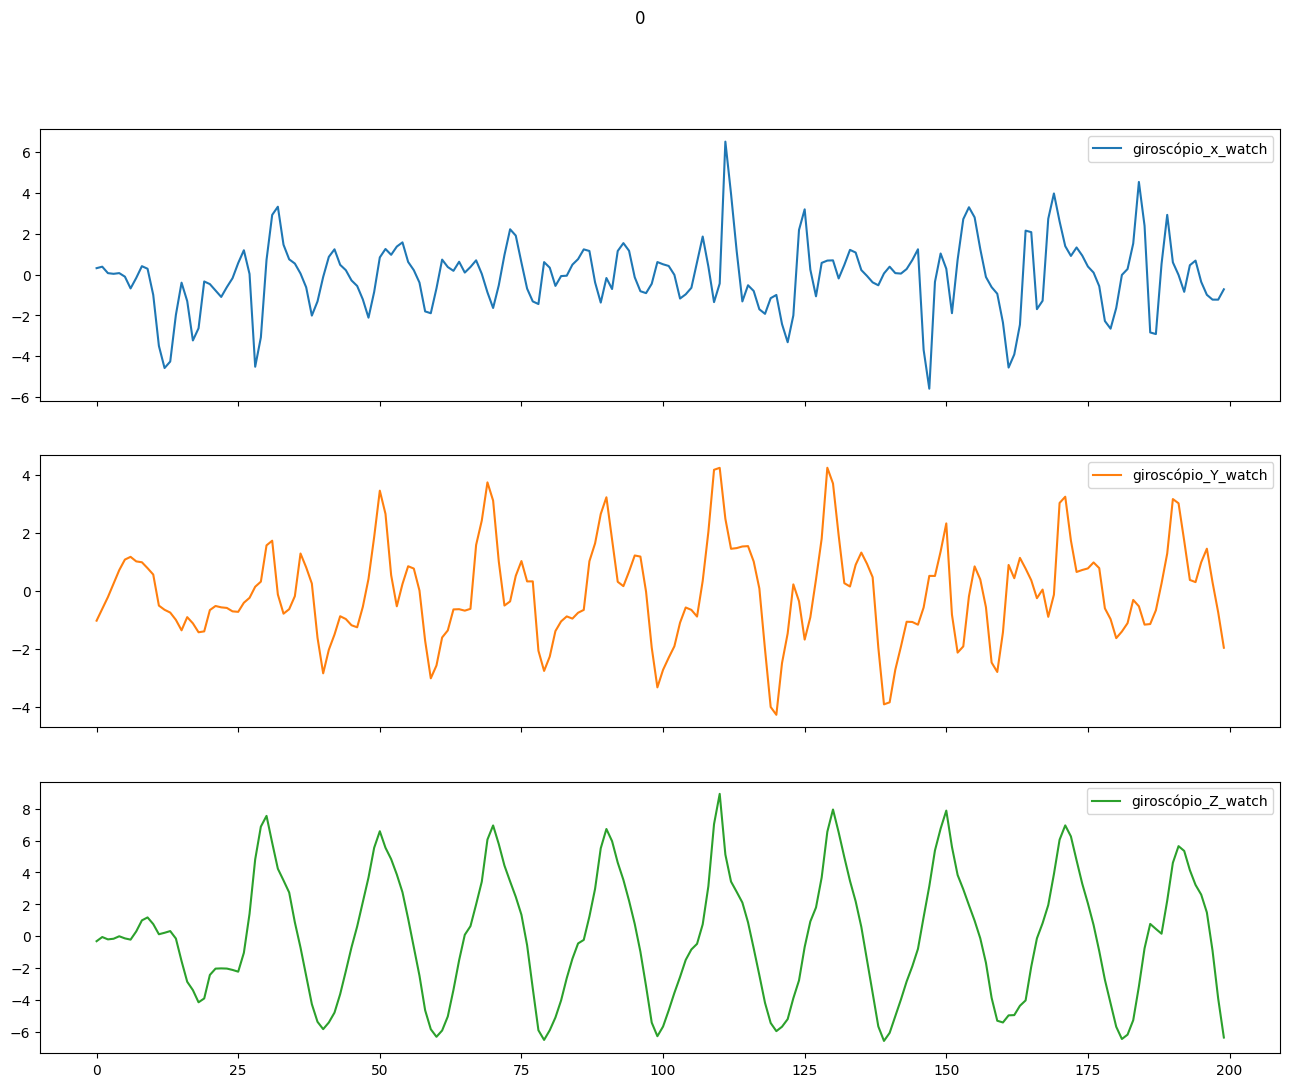

In [122]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x_watch','giroscópio_Y_watch','giroscópio_Z_watch']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

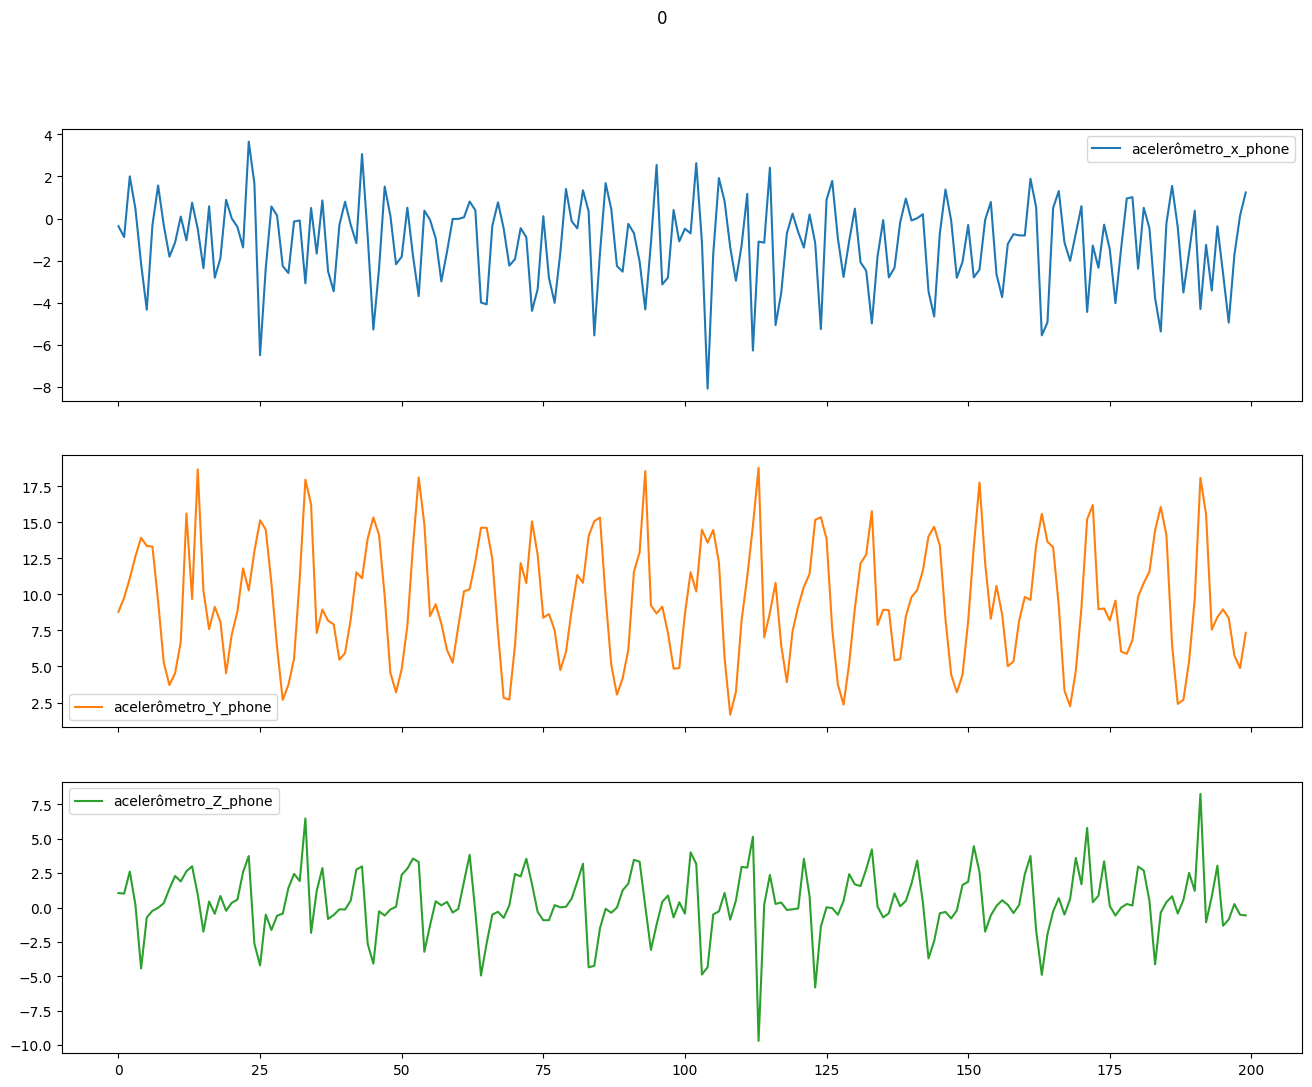

In [123]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x_phone','acelerômetro_Y_phone','acelerômetro_Z_phone']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

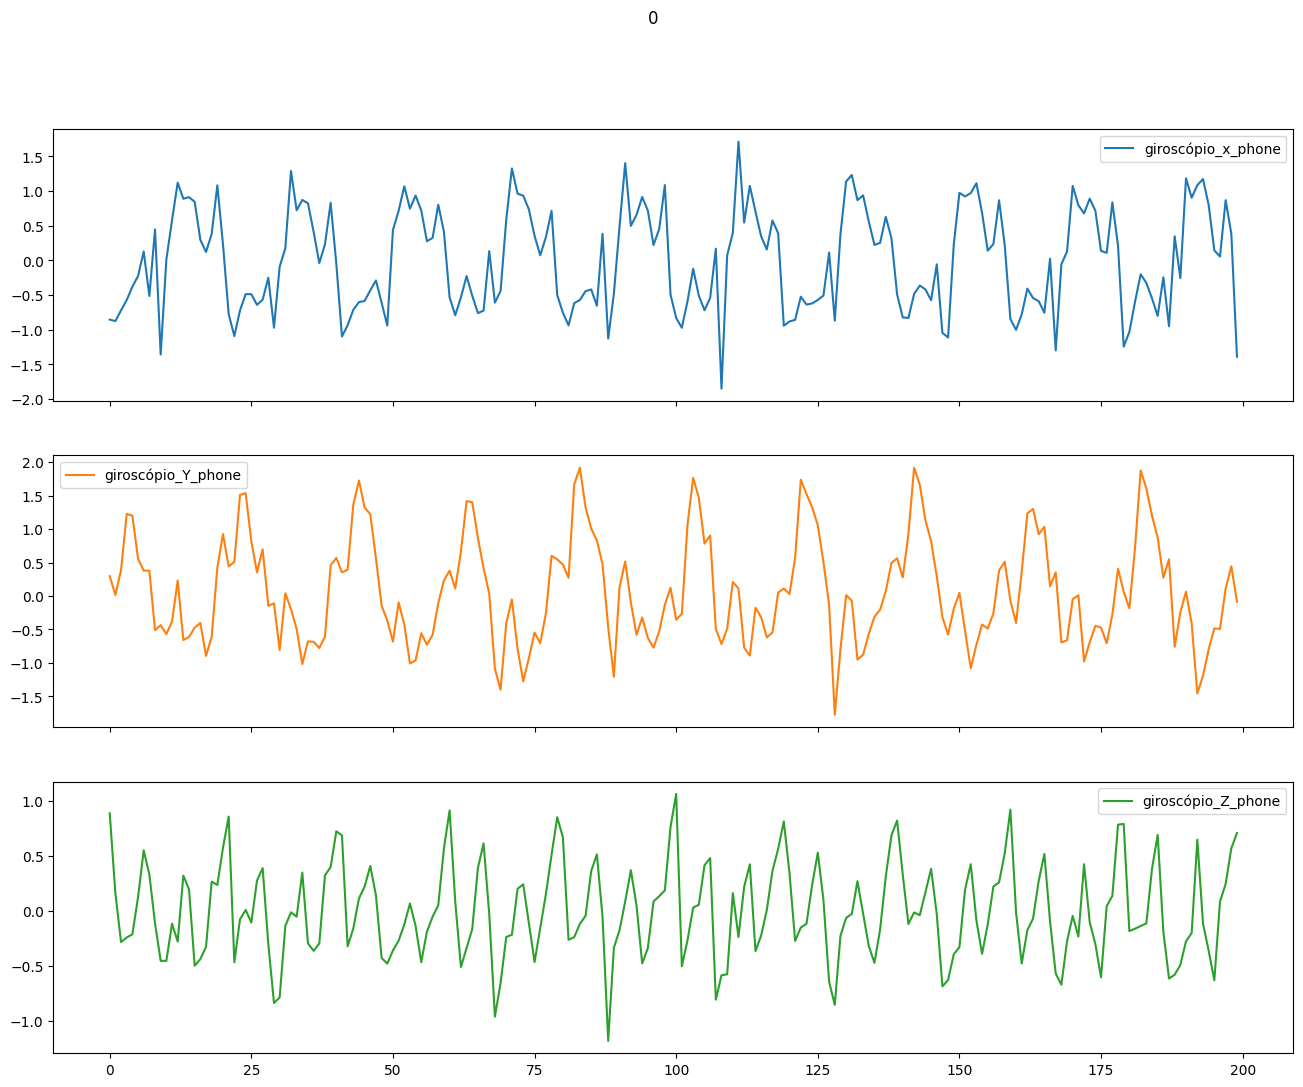

In [124]:
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x_phone','giroscópio_Y_phone','giroscópio_Z_phone']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [125]:
#data = data[data.pessoa_x!=1629]

In [126]:
data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1610,
       1611, 1612, 1613, 1614, 1615, 1616, 1617, 1618, 1619, 1620, 1621,
       1622, 1623, 1624, 1625, 1626, 1627, 1628, 1629, 1630, 1631, 1632,
       1633, 1634, 1635, 1636, 1637, 1638, 1639, 1640, 1641, 1642, 1643,
       1644, 1645, 1646, 1647, 1648, 1649, 1650], dtype=int64)

In [127]:
data = data.reset_index(drop=True)

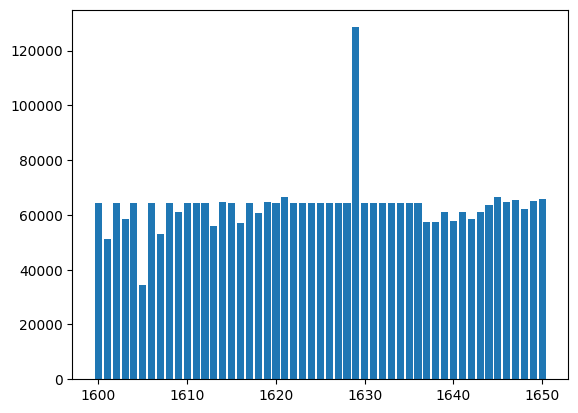

In [128]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [129]:
data = data[data.pessoa_x!=1629]

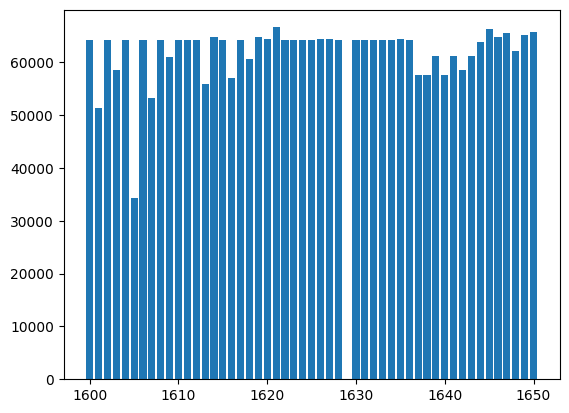

In [130]:
plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [131]:
#selecting only activities 0 to 3
#data = data[data["atividade"].isin([0,1,2,3,13,16])]

In [132]:
# Define the mapping dictionary
#mapping_dict = {13:4,16:5}

In [133]:
#data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [134]:
data.shape

(3102873, 18)

In [135]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600,252207666810782,-0.36476135,8.793503,1.05508420,252207918580802,-0.85321045,0.297225950,0.89018250
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802,252207717164786,-0.87973020,9.768784,1.01699830,252207968934806,-0.87513730,0.015472412,0.16223145
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300,252207767518790,2.00149540,11.109070,2.61915600,252208019288809,-0.72016907,0.388488770,-0.28401184
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500,252207817872794,0.45062256,12.651642,0.18455505,252208069642813,-0.57164000,1.227401700,-0.24166870
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904,252207868226798,-2.16435240,13.928436,-4.42248540,252208119996817,-0.38049316,1.202835100,-0.21313477


In [136]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600,252207666810782,-0.36476135,8.793503,1.05508420,252207918580802,-0.85321045,0.297225950,0.89018250
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802,252207717164786,-0.87973020,9.768784,1.01699830,252207968934806,-0.87513730,0.015472412,0.16223145
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300,252207767518790,2.00149540,11.109070,2.61915600,252208019288809,-0.72016907,0.388488770,-0.28401184
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500,252207817872794,0.45062256,12.651642,0.18455505,252208069642813,-0.57164000,1.227401700,-0.24166870
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904,252207868226798,-2.16435240,13.928436,-4.42248540,252208119996817,-0.38049316,1.202835100,-0.21313477


In [137]:
data.shape

(3102873, 18)

# **Models**

In [138]:
columns_to_scale = ['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
       'giroscópio_x_watch', 'giroscópio_Y_watch', 'giroscópio_Z_watch',
       'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone',
       'giroscópio_x_phone', 'giroscópio_Y_phone', 'giroscópio_Z_phone']

In [139]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_to_scale = data[columns_to_scale]
scaler.fit(df_to_scale)
data[columns_to_scale] = scaler.transform(df_to_scale)

In [140]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,0.933088891,0.692106823,1.167038477,90426757696641,0.216199697,-0.662397670,-0.229386319,252207666810782,-0.098874748,1.599604687,0.084353289,252207918580802,-1.006320118,0.315418337,1.345733412
1,1600,0,90426757696641,0.631282547,0.773589811,0.881585705,90426807196641,0.261977781,-0.392880959,-0.044821751,252207717164786,-0.187314917,1.744233217,0.076907388,252207968934806,-1.032301790,0.021692917,0.246720937
2,1600,0,90426807196641,0.386427147,0.767287256,0.769410988,90426856696641,0.062035305,-0.119808660,-0.148780569,252207767518790,0.307503511,1.942989877,0.390133737,252208019288809,-0.848676067,0.410558970,-0.426987745
3,1600,0,90426856696641,0.321973590,0.774039993,0.748435280,90426906196641,0.041165891,0.190242187,-0.120907542,252207817872794,0.041158363,2.171744381,-0.085837615,252208069642813,-0.672680266,1.285117827,-0.363060865
4,1600,0,90426906196641,0.460088378,0.605671837,1.078575510,90426955696641,0.063381719,0.500293048,-0.010922139,252207868226798,-0.407934481,2.361085545,-0.986527015,252208119996817,-0.446185606,1.259507377,-0.319982220


In [141]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [142]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
                           'giroscópio_x_watch', 'giroscópio_Y_watch','giroscópio_Z_watch', 
                           'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone'
                           , 'giroscópio_x_phone', 'giroscópio_Y_phone','giroscópio_Z_phone']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [143]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
                           'giroscópio_x_watch', 'giroscópio_Y_watch','giroscópio_Z_watch', 
                           'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone'
                           , 'giroscópio_x_phone', 'giroscópio_Y_phone','giroscópio_Z_phone']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [144]:
participants_x_test = [1600,1610,1620,1630,1640]

In [145]:
X_test_data = data[data.pessoa_x.isin(participants_x_test)]

In [146]:
print(X_test_data.shape)

(314660, 18)


In [147]:
X_test_data['atividade'].value_counts().sort_index()

atividade
0     17876
1     17875
2     14276
3     17885
4     14280
5     17874
6     17880
7     17892
8     17887
9     17872
10    17887
11    17889
12    17894
13    17877
14    17877
15    17887
16    17876
17    17876
Name: count, dtype: int64

In [148]:
X_test_data = X_test_data.reset_index(drop = True)

In [149]:
#X_test_data = X_test_data.sort_values(by=['pessoa_x','atividade'])

In [150]:
X_test_data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,0.933088891,0.692106823,1.167038477,90426757696641,0.216199697,-0.662397670,-0.229386319,252207666810782,-0.098874748,1.599604687,0.084353289,252207918580802,-1.006320118,0.315418337,1.345733412
1,1600,0,90426757696641,0.631282547,0.773589811,0.881585705,90426807196641,0.261977781,-0.392880959,-0.044821751,252207717164786,-0.187314917,1.744233217,0.076907388,252207968934806,-1.032301790,0.021692917,0.246720937
2,1600,0,90426807196641,0.386427147,0.767287256,0.769410988,90426856696641,0.062035305,-0.119808660,-0.148780569,252207767518790,0.307503511,1.942989877,0.390133737,252208019288809,-0.848676067,0.410558970,-0.426987745
3,1600,0,90426856696641,0.321973590,0.774039993,0.748435280,90426906196641,0.041165891,0.190242187,-0.120907542,252207817872794,0.041158363,2.171744381,-0.085837615,252208069642813,-0.672680266,1.285117827,-0.363060865
4,1600,0,90426906196641,0.460088378,0.605671837,1.078575510,90426955696641,0.063381719,0.500293048,-0.010922139,252207868226798,-0.407934481,2.361085545,-0.986527015,252208119996817,-0.446185606,1.259507377,-0.319982220


In [151]:
X_test_data.tail()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
314655,1640,17,168330572967000,-0.242819100,-0.910170478,-0.162135733,168403141149000,0.024572182,0.057009749,-0.013956908,170599479646218,0.366645809,-0.819177425,-1.163001155,170599529632748,0.610091997,-0.569019756,-0.689723165
314656,1640,17,168330593063000,-0.234972871,-0.910170478,-0.148907361,168403181405000,0.029957837,0.064832134,-0.019983506,170599529632748,0.549619784,-0.828053575,-1.041770169,170599579619278,0.558339369,-0.495724899,-0.746012481
314657,1640,17,168330613274000,-0.216210129,-0.916475224,-0.161223421,168403221772000,0.027938216,0.057720877,-0.016970207,170599579619278,0.594026956,-0.864623374,-1.039897917,170599629605808,0.507849018,-0.435756387,-0.791043937
314658,1640,17,168330633370000,-0.189942297,-0.934038186,-0.173539500,168403262083000,0.024572182,0.063409881,-0.017723532,170599629605808,0.585392218,-0.781187517,-0.959389327,170599679592338,-0.210375990,-0.158124331,-0.639866947
314659,1640,17,168330653583000,-0.188577731,-0.940343027,-0.189960900,168403302333000,0.023225768,0.059143127,-0.022996806,170599679592338,0.577579868,-0.776571845,-1.035685261,170599729578868,-0.190179856,-0.051513632,-0.594835491


In [152]:
#test10 = X_test_data[X_test_data['atividade']==17]

In [153]:
#test10.tail()

In [154]:
X_test_data.pessoa_x.unique()

array([1600, 1610, 1620, 1630, 1640], dtype=int64)

In [155]:
print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

percentage of validation is 0.10140924233766577


In [156]:
X_test_data['atividade'].value_counts().sort_index()

atividade
0     17876
1     17875
2     14276
3     17885
4     14280
5     17874
6     17880
7     17892
8     17887
9     17872
10    17887
11    17889
12    17894
13    17877
14    17877
15    17887
16    17876
17    17876
Name: count, dtype: int64

In [157]:
data.columns

Index(['pessoa_x', 'atividade', 'tempo_acelerômetro_watch',
       'acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
       'tempo_gyro_watch', 'giroscópio_x_watch', 'giroscópio_Y_watch',
       'giroscópio_Z_watch', 'tempo_acelerômetro_phone',
       'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone',
       'tempo_giroscópio_phone', 'giroscópio_x_phone', 'giroscópio_Y_phone',
       'giroscópio_Z_phone'],
      dtype='object')

In [158]:
X_test_data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1600,0,90426708196641,0.933088891,0.692106823,1.167038477,90426757696641,0.216199697,-0.662397670,-0.229386319,252207666810782,-0.098874748,1.599604687,0.084353289,252207918580802,-1.006320118,0.315418337,1.345733412
1,1600,0,90426757696641,0.631282547,0.773589811,0.881585705,90426807196641,0.261977781,-0.392880959,-0.044821751,252207717164786,-0.187314917,1.744233217,0.076907388,252207968934806,-1.032301790,0.021692917,0.246720937
2,1600,0,90426807196641,0.386427147,0.767287256,0.769410988,90426856696641,0.062035305,-0.119808660,-0.148780569,252207767518790,0.307503511,1.942989877,0.390133737,252208019288809,-0.848676067,0.410558970,-0.426987745
3,1600,0,90426856696641,0.321973590,0.774039993,0.748435280,90426906196641,0.041165891,0.190242187,-0.120907542,252207817872794,0.041158363,2.171744381,-0.085837615,252208069642813,-0.672680266,1.285117827,-0.363060865
4,1600,0,90426906196641,0.460088378,0.605671837,1.078575510,90426955696641,0.063381719,0.500293048,-0.010922139,252207868226798,-0.407934481,2.361085545,-0.986527015,252208119996817,-0.446185606,1.259507377,-0.319982220


In [159]:
X_test_data.tail()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
314655,1640,17,168330572967000,-0.242819100,-0.910170478,-0.162135733,168403141149000,0.024572182,0.057009749,-0.013956908,170599479646218,0.366645809,-0.819177425,-1.163001155,170599529632748,0.610091997,-0.569019756,-0.689723165
314656,1640,17,168330593063000,-0.234972871,-0.910170478,-0.148907361,168403181405000,0.029957837,0.064832134,-0.019983506,170599529632748,0.549619784,-0.828053575,-1.041770169,170599579619278,0.558339369,-0.495724899,-0.746012481
314657,1640,17,168330613274000,-0.216210129,-0.916475224,-0.161223421,168403221772000,0.027938216,0.057720877,-0.016970207,170599579619278,0.594026956,-0.864623374,-1.039897917,170599629605808,0.507849018,-0.435756387,-0.791043937
314658,1640,17,168330633370000,-0.189942297,-0.934038186,-0.173539500,168403262083000,0.024572182,0.063409881,-0.017723532,170599629605808,0.585392218,-0.781187517,-0.959389327,170599679592338,-0.210375990,-0.158124331,-0.639866947
314659,1640,17,168330653583000,-0.188577731,-0.940343027,-0.189960900,168403302333000,0.023225768,0.059143127,-0.022996806,170599679592338,0.577579868,-0.776571845,-1.035685261,170599729578868,-0.190179856,-0.051513632,-0.594835491


In [160]:
X_test_data = X_test_data[['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
                           'giroscópio_x_watch', 'giroscópio_Y_watch','giroscópio_Z_watch', 
                           'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone'
                           , 'giroscópio_x_phone', 'giroscópio_Y_phone','giroscópio_Z_phone','atividade']]

In [161]:
X_test_data.atividade.value_counts()

atividade
12    17894
7     17892
11    17889
15    17887
8     17887
10    17887
3     17885
6     17880
14    17877
13    17877
0     17876
16    17876
17    17876
1     17875
5     17874
9     17872
4     14280
2     14276
Name: count, dtype: int64

In [162]:
X_train_validation_data = data[~data.pessoa_x.isin(participants_x_test)]

In [163]:
print(X_train_validation_data.shape)

(2788213, 18)


In [164]:
X_train_validation_data = X_train_validation_data.reset_index(drop = True)

In [165]:
X_train_validation_data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1601,0,1896411611733301,-0.500022624,0.436825355,1.649110650,1896411611733301,0.461664059,-0.271229578,-0.684753618,265073308304101,0.771527098,1.649104183,-0.109397691,265073308304101,-0.019312676,0.001120960,-0.033587256
1,1601,0,1896411661695801,-0.573683841,0.348139422,1.826948496,1896411661695801,0.178243941,-0.263407187,-0.712626609,265073348330612,0.883367400,2.614208644,-0.244904877,265073348330612,-1.433357651,0.063310538,-0.556273698
2,1601,0,1896411711658874,-0.479561158,0.266656438,1.471272613,1896411711658874,0.207865050,-0.128293283,-0.681740290,265073388368581,1.062846368,2.212562512,-0.033920887,265073388368581,-2.859709878,1.177725656,-2.480966041
3,1601,0,1896411761623926,-0.548107016,0.224789538,1.496808266,1896411761623926,0.199113364,-0.074247719,-0.784945829,265073428111445,1.772538699,2.254191812,-0.322253965,265073428111445,-3.639154341,1.600836736,-2.523987120
4,1601,0,1896411811593717,-0.646321987,0.268007040,1.373689567,1896411811593717,0.271819709,0.201669092,-0.721666561,265073468081082,2.733871580,0.693497137,0.101469268,265073468081082,0.017923947,4.776947338,-0.366096246


In [166]:
X_train_validation_data.tail()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
2788208,1650,17,2426184321449912,0.602252851,-0.212281189,1.050617289,2426184371437252,-1.787758193,1.393265814,0.593686894,357626608042000,-1.285815014,-0.490761942,-0.479648730,357699155079000,0.053898312,-0.166568807,-0.266785835
2788209,1650,17,2426184371437252,0.227467237,-0.552618985,1.142272274,2426184421424592,-1.822764922,1.233262503,0.895770128,357626628138000,-1.263192505,-0.514202957,-0.516639135,357699195384000,0.258384172,-0.298721652,-0.173506405
2788210,1650,17,2426184421424592,0.134708678,-1.697882511,0.626086222,2426184471411932,-1.888739130,1.054769905,1.444943808,357626648248000,-1.266483056,-0.525213106,-0.548947246,357699235690000,0.618127862,-0.117705563,-0.154207203
2788211,1650,17,2426184471411932,0.495171286,-1.668620686,0.580942654,2426184521399272,-2.016648422,1.085348335,2.124442775,357626668344000,-1.292396116,-0.538709511,-0.532090837,357699275996000,0.471705844,0.041099976,-0.105959228
2788212,1650,17,2426184521399272,0.551440224,-2.076936179,0.248066457,2426184571385262,-1.534632400,0.598227174,2.361739998,357626688550000,-1.281290519,-0.584170971,-0.433293663,357699316371000,0.296251933,0.182137048,0.082207899


In [167]:
X_train_validation_data.pessoa_x.unique()

array([1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1611, 1612,
       1613, 1614, 1615, 1616, 1617, 1618, 1619, 1621, 1622, 1623, 1624,
       1625, 1626, 1627, 1628, 1631, 1632, 1633, 1634, 1635, 1636, 1637,
       1638, 1639, 1641, 1642, 1643, 1644, 1645, 1646, 1647, 1648, 1649,
       1650], dtype=int64)

In [168]:
print(f"percentage of validation is {X_train_validation_data.shape[0]/data.shape[0]}")

percentage of validation is 0.8985907576623342


In [169]:
X_train_validation_data['atividade'].value_counts().sort_index()

atividade
0     155853
1     148481
2     153158
3     155909
4     155003
5     155039
6     157702
7     160254
8     151404
9     152327
10    155894
11    154095
12    155555
13    148676
14    158540
15    154988
16    157671
17    157664
Name: count, dtype: int64

In [170]:
participants_x_validation = [1601,1602,1611,1612,1621,1622,1631,1632,1641,1642]

In [171]:
X_validation_data = X_train_validation_data[X_train_validation_data.pessoa_x.isin(participants_x_validation)]

In [172]:
print(X_validation_data.shape)

(623152, 18)


In [173]:
X_validation_data = X_validation_data.reset_index(drop = True)

In [174]:
X_validation_data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1601,0,1896411611733301,-0.500022624,0.436825355,1.649110650,1896411611733301,0.461664059,-0.271229578,-0.684753618,265073308304101,0.771527098,1.649104183,-0.109397691,265073308304101,-0.019312676,0.001120960,-0.033587256
1,1601,0,1896411661695801,-0.573683841,0.348139422,1.826948496,1896411661695801,0.178243941,-0.263407187,-0.712626609,265073348330612,0.883367400,2.614208644,-0.244904877,265073348330612,-1.433357651,0.063310538,-0.556273698
2,1601,0,1896411711658874,-0.479561158,0.266656438,1.471272613,1896411711658874,0.207865050,-0.128293283,-0.681740290,265073388368581,1.062846368,2.212562512,-0.033920887,265073388368581,-2.859709878,1.177725656,-2.480966041
3,1601,0,1896411761623926,-0.548107016,0.224789538,1.496808266,1896411761623926,0.199113364,-0.074247719,-0.784945829,265073428111445,1.772538699,2.254191812,-0.322253965,265073428111445,-3.639154341,1.600836736,-2.523987120
4,1601,0,1896411811593717,-0.646321987,0.268007040,1.373689567,1896411811593717,0.271819709,0.201669092,-0.721666561,265073468081082,2.733871580,0.693497137,0.101469268,265073468081082,0.017923947,4.776947338,-0.366096246


In [175]:
X_validation_data.tail()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
623147,1642,17,1473403730675549,-0.378554070,0.087680900,0.864143945,1473403780670859,0.985339123,-0.191333697,0.118397730,1471166553308000,0.125005596,1.791900020,-0.268007377,1471239061678000,0.052636051,-0.028863300,-0.114000555
623148,1642,17,1473403780670859,-0.267380174,0.999299933,1.915668009,1473403830666169,-1.043033366,0.464324288,0.182430327,1471166573404000,0.127062186,1.787993060,-0.297974286,1471239101980000,0.063996381,-0.152131939,-0.072185637
623149,1642,17,1473403830666169,-0.497230478,0.130898384,1.616535480,1473403880661479,0.168065904,1.415810583,0.232149779,1471166593628000,0.127062186,1.794386172,-0.312021281,1471239142266000,0.050111537,-0.185447770,-0.033587256
623150,1642,17,1473403880661479,-0.520420135,0.445575754,1.152788792,1473403930656789,-1.018124699,1.143449447,0.131957568,1471166613724000,0.138167766,1.794386172,-0.319513016,1471239182547000,0.051373797,-0.232089958,-0.046453379
623151,1642,17,1473403930656789,-0.651714473,0.477088527,0.244903007,1473403980652099,0.061699208,-0.002174229,0.302208949,1471166633862000,0.143926222,1.791900020,-0.323727118,1471239222851000,0.034964436,-0.223205738,-0.083443504


In [176]:
X_validation_data.pessoa_x.unique()

array([1601, 1602, 1611, 1612, 1621, 1622, 1631, 1632, 1641, 1642],
      dtype=int64)

In [177]:
print(f"percentage of validation is {X_validation_data.shape[0]/X_train_validation_data.shape[0]}")

percentage of validation is 0.22349512035127875


In [178]:
X_validation_data['atividade'].value_counts()

atividade
3     37638
11    37587
9     36738
0     36735
7     36735
6     35818
13    35817
14    35815
17    35812
16    35809
4     33124
8     32224
10    32223
5     32217
1     32216
2     32215
15    32215
12    32214
Name: count, dtype: int64

In [179]:
X_validation_data = X_validation_data[['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
                           'giroscópio_x_watch', 'giroscópio_Y_watch','giroscópio_Z_watch', 
                           'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone'
                           , 'giroscópio_x_phone', 'giroscópio_Y_phone','giroscópio_Z_phone','atividade']]

In [180]:
X_train_data = X_train_validation_data[~X_train_validation_data.pessoa_x.isin(participants_x_validation)]

In [181]:
X_train_data.pessoa_x.unique()

array([1603, 1604, 1605, 1606, 1607, 1608, 1609, 1613, 1614, 1615, 1616,
       1617, 1618, 1619, 1623, 1624, 1625, 1626, 1627, 1628, 1633, 1634,
       1635, 1636, 1637, 1638, 1639, 1643, 1644, 1645, 1646, 1647, 1648,
       1649, 1650], dtype=int64)

In [182]:
X_train_data.shape

(2165061, 18)

In [183]:
X_train_data = X_train_data.reset_index(drop=True)

In [184]:
print(f"percentage of validation is {X_train_data.shape[0]/X_train_validation_data.shape[0]}")

percentage of validation is 0.7765048796487213


In [185]:
X_train_data.head()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
0,1603,1,8470469898733,0.401709313,0.198059916,-1.619574208,8470469898733,-0.430069041,-0.363672559,0.272792578,8746412162032,1.941635366,0.492807269,-0.472739504,8746458096305,-0.019312676,0.001120960,-0.033587256
1,1603,1,8470519840269,0.367947913,0.163846127,-1.271650155,8470519840269,0.492224453,0.569324516,0.434004057,8746458096305,1.941635366,0.492807269,-0.472739504,8746480136513,-2.391096350,-0.311492725,-3.159252100
2,1603,1,8470569777258,0.867889390,-1.267283182,-1.737220859,8470569777258,0.382491724,0.588524926,0.395584486,8746480136513,2.149074625,1.284294112,-0.579694249,8746521944481,-1.935105354,-0.056904139,-2.980734656
3,1603,1,8470619714820,1.039424597,0.002230667,-0.769599931,8470619714820,1.685820397,0.325408374,0.104801154,8746521944481,1.239447165,1.047123229,-0.524344585,8746559886095,-2.002320696,2.050323140,-2.152879699
4,1603,1,8470669655171,1.184359821,-1.079557208,-0.993493391,8470669655171,0.724480829,0.545146232,0.217799875,8746559886095,1.044754589,1.358587586,0.769994817,8746600065940,0.427526818,0.832628945,-0.426808328


In [186]:
X_train_data.tail()

,pessoa_x,atividade,tempo_acelerômetro_watch,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,tempo_gyro_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,tempo_acelerômetro_phone,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,tempo_giroscópio_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone
2165056,1650,17,2426184321449912,0.602252851,-0.212281189,1.050617289,2426184371437252,-1.787758193,1.393265814,0.593686894,357626608042000,-1.285815014,-0.490761942,-0.479648730,357699155079000,0.053898312,-0.166568807,-0.266785835
2165057,1650,17,2426184371437252,0.227467237,-0.552618985,1.142272274,2426184421424592,-1.822764922,1.233262503,0.895770128,357626628138000,-1.263192505,-0.514202957,-0.516639135,357699195384000,0.258384172,-0.298721652,-0.173506405
2165058,1650,17,2426184421424592,0.134708678,-1.697882511,0.626086222,2426184471411932,-1.888739130,1.054769905,1.444943808,357626648248000,-1.266483056,-0.525213106,-0.548947246,357699235690000,0.618127862,-0.117705563,-0.154207203
2165059,1650,17,2426184471411932,0.495171286,-1.668620686,0.580942654,2426184521399272,-2.016648422,1.085348335,2.124442775,357626668344000,-1.292396116,-0.538709511,-0.532090837,357699275996000,0.471705844,0.041099976,-0.105959228
2165060,1650,17,2426184521399272,0.551440224,-2.076936179,0.248066457,2426184571385262,-1.534632400,0.598227174,2.361739998,357626688550000,-1.281290519,-0.584170971,-0.433293663,357699316371000,0.296251933,0.182137048,0.082207899


In [187]:
X_train_data['atividade'].value_counts()

atividade
10    123671
7     123519
12    123341
5     122822
15    122773
14    122725
6     121884
4     121879
16    121862
17    121852
2     120943
8     119180
0     119118
3     118271
11    116508
1     116265
9     115589
13    112859
Name: count, dtype: int64

In [188]:
X_train_data = X_train_data[['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
                           'giroscópio_x_watch', 'giroscópio_Y_watch','giroscópio_Z_watch', 
                           'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone'
                           , 'giroscópio_x_phone', 'giroscópio_Y_phone','giroscópio_Z_phone','atividade']]

In [189]:
X_train_data.head()

,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone,atividade
0,0.401709313,0.198059916,-1.619574208,-0.430069041,-0.363672559,0.272792578,1.941635366,0.492807269,-0.472739504,-0.019312676,0.001120960,-0.033587256,1
1,0.367947913,0.163846127,-1.271650155,0.492224453,0.569324516,0.434004057,1.941635366,0.492807269,-0.472739504,-2.391096350,-0.311492725,-3.159252100,1
2,0.867889390,-1.267283182,-1.737220859,0.382491724,0.588524926,0.395584486,2.149074625,1.284294112,-0.579694249,-1.935105354,-0.056904139,-2.980734656,1
3,1.039424597,0.002230667,-0.769599931,1.685820397,0.325408374,0.104801154,1.239447165,1.047123229,-0.524344585,-2.002320696,2.050323140,-2.152879699,1
4,1.184359821,-1.079557208,-0.993493391,0.724480829,0.545146232,0.217799875,1.044754589,1.358587586,0.769994817,0.427526818,0.832628945,-0.426808328,1


In [190]:
X_test_data.head()

,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone,atividade
0,0.933088891,0.692106823,1.167038477,0.216199697,-0.662397670,-0.229386319,-0.098874748,1.599604687,0.084353289,-1.006320118,0.315418337,1.345733412,0
1,0.631282547,0.773589811,0.881585705,0.261977781,-0.392880959,-0.044821751,-0.187314917,1.744233217,0.076907388,-1.032301790,0.021692917,0.246720937,0
2,0.386427147,0.767287256,0.769410988,0.062035305,-0.119808660,-0.148780569,0.307503511,1.942989877,0.390133737,-0.848676067,0.410558970,-0.426987745,0
3,0.321973590,0.774039993,0.748435280,0.041165891,0.190242187,-0.120907542,0.041158363,2.171744381,-0.085837615,-0.672680266,1.285117827,-0.363060865,0
4,0.460088378,0.605671837,1.078575510,0.063381719,0.500293048,-0.010922139,-0.407934481,2.361085545,-0.986527015,-0.446185606,1.259507377,-0.319982220,0


In [191]:
X_test_data.columns

Index(['acelerômetro_x_watch', 'acelerômetro_Y_watch', 'acelerômetro_Z_watch',
       'giroscópio_x_watch', 'giroscópio_Y_watch', 'giroscópio_Z_watch',
       'acelerômetro_x_phone', 'acelerômetro_Y_phone', 'acelerômetro_Z_phone',
       'giroscópio_x_phone', 'giroscópio_Y_phone', 'giroscópio_Z_phone',
       'atividade'],
      dtype='object')

In [192]:
X_test_data.head()

,acelerômetro_x_watch,acelerômetro_Y_watch,acelerômetro_Z_watch,giroscópio_x_watch,giroscópio_Y_watch,giroscópio_Z_watch,acelerômetro_x_phone,acelerômetro_Y_phone,acelerômetro_Z_phone,giroscópio_x_phone,giroscópio_Y_phone,giroscópio_Z_phone,atividade
0,0.933088891,0.692106823,1.167038477,0.216199697,-0.662397670,-0.229386319,-0.098874748,1.599604687,0.084353289,-1.006320118,0.315418337,1.345733412,0
1,0.631282547,0.773589811,0.881585705,0.261977781,-0.392880959,-0.044821751,-0.187314917,1.744233217,0.076907388,-1.032301790,0.021692917,0.246720937,0
2,0.386427147,0.767287256,0.769410988,0.062035305,-0.119808660,-0.148780569,0.307503511,1.942989877,0.390133737,-0.848676067,0.410558970,-0.426987745,0
3,0.321973590,0.774039993,0.748435280,0.041165891,0.190242187,-0.120907542,0.041158363,2.171744381,-0.085837615,-0.672680266,1.285117827,-0.363060865,0
4,0.460088378,0.605671837,1.078575510,0.063381719,0.500293048,-0.010922139,-0.407934481,2.361085545,-0.986527015,-0.446185606,1.259507377,-0.319982220,0


In [193]:
segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data)
print(targets_test.shape)
print(segments_test.shape)

(1573, 200, 1)
(1573, 200, 12)


In [194]:
segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)
print(targets_test.shape)
print(segments_test.shape)

(1486, 200, 1)
(1486, 200, 12)


In [195]:
print(segments_test)

[[[ 0.9330889   0.69210684  1.1670384  ... -1.0063201   0.31541833
    1.3457334 ]
  [ 0.63128257  0.7735898   0.8815857  ... -1.0323018   0.02169292
    0.24672094]
  [ 0.38642713  0.76728725  0.76941097 ... -0.8486761   0.41055897
   -0.42698774]
  ...
  [ 0.80827415  0.9797733  -0.8794662  ...  1.0330179   0.12415083
    0.37455165]
  [ 1.0316449   0.8051026  -0.81790686 ...  0.45955804  0.46989262
    0.86454254]
  [ 1.4565611   0.40173927 -0.46223095 ... -1.6407474  -0.08311926
    1.0745913 ]]

 [[ 2.4387107   0.24417551 -0.44307914 ... -0.90740156 -0.10134884
    0.72862595]
  [ 2.0785892   0.18880306 -0.44262317 ... -0.9808628   0.5126033
   -0.4308349 ]
  [ 1.2359184   0.6520406  -0.5598138  ... -0.3972597   1.8309078
   -0.38469234]
  ...
  [ 1.1070112   0.71866757 -0.49962252 ...  0.7802884   0.14570501
    0.37915897]
  [ 1.7096009   0.66869736 -0.5538859  ...  0.8115134   0.49119228
    0.97332186]
  [ 1.4306432   1.1382375  -0.9373775  ... -0.14264984  0.23635983
    1.47

In [196]:
targets_test = targets_test.reshape(targets_test.shape[0],200)

In [197]:
print(targets_test.shape)

(1486, 200)


In [198]:
print(targets_test)

[[ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 ...
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]]


In [199]:
labels_test = targets_test[:,0]

In [200]:
print(labels_test)

[ 0  0  0 ... 17 17 17]


In [201]:
print(labels_test.shape)

(1486,)


In [202]:
labels_test_categorical = to_categorical(labels_test,num_classes=18)

In [203]:
print(labels_test_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [204]:
print(labels_test_categorical.shape)

(1486, 18)


In [205]:
segments_val,targets_val = apply_segmentation_no_sliding_window(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(3115, 200, 1)
(3115, 200, 12)


In [206]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(2944, 200, 1)
(2944, 200, 12)


In [207]:
targets_val = targets_val.reshape(targets_val.shape[0],200)

In [208]:
print(targets_val.shape)

(2944, 200)


In [209]:
print(targets_val)

[[ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 ...
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]]


In [210]:
labels_val = targets_val[:,0]

In [211]:
print(labels_val)

[ 0  0  0 ... 17 17 17]


In [212]:
print(labels_val.shape)

(2944,)


In [213]:
labels_val_categorical = to_categorical(labels_val,num_classes=18)

In [214]:
print(labels_val_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [215]:
print(labels_val_categorical.shape)

(2944, 18)


In [216]:
segments_train,targets_train = apply_segmentation_no_sliding_window(X_train_data)

In [217]:
print(segments_train.shape)
print(targets_train.shape)

(10825, 200, 12)
(10825, 200, 1)


In [218]:
segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [219]:
print(segments_train.shape)
print(targets_train.shape)

(10228, 200, 12)
(10228, 200, 1)


In [220]:
targets_train = targets_train.reshape(targets_train.shape[0],200)

In [221]:
print(targets_train.shape)

(10228, 200)


In [222]:
labels_train = targets_train[:,0]

In [223]:
labels_train_categorical = to_categorical(labels_train,num_classes=18)

In [224]:
print(labels_train_categorical)

[[0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [225]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [226]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(10228, 200, 12)
(10228, 18)
(2944, 200, 12)
(2944, 18)


In [227]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [228]:
''' X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation) '''

' X_train,y_train = shuffle_data(X_train,y_train)\nX_validation,y_validation = shuffle_data(X_validation,y_validation) '

In [229]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(10228, 200, 12)
(10228, 18)
(2944, 200, 12)
(2944, 18)


In [230]:
#from tensorflow.keras import regularizers

In [231]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [232]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=512,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.0001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.0001, max_value=0.1, sampling='log')), input_shape=(200,12), return_sequences=True)) 
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=512,step=32), activation='relu'))  
  model.add(tf.keras.layers.Flatten())
  model.add(tf.keras.layers.Dense(units=18, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model '''


' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=512,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.0001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.0001, max_value=0.1, sampling=\'log\')), input_shape=(200,12), return_sequences=True)) \n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=512,step=32), activation=\'relu\'))  \n  model.add(tf.keras.layers.Flatten())\n  model.add(tf.keras.layers.Dense(units=18, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model '

In [239]:
import tensorflow as tf
from tensorflow.keras.layers import ConvLSTM2D, Dense, Flatten
from tensorflow.keras.regularizers import l2
from kerastuner import HyperParameters

def cria_ConvLSTM(hp):
    model = tf.keras.Sequential()
    model.add(ConvLSTM2D(
        filters=hp.Int("filters", min_value=32, max_value=512, step=32),
        kernel_size=(3, 3),
        kernel_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')),
        recurrent_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')),
        input_shape=(20,200, 12, 1),
        return_sequences=True
    ))
    model.add(Flatten())
    model.add(Dense(units=hp.Int("dense_units", min_value=32, max_value=512, step=32), activation='relu'))
    model.add(Dense(units=18, activation='softmax'))

    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(
                      hp.Float('learning_rate',
                               min_value=1e-4,
                               max_value=1e-2,
                               sampling='log',
                               default=1e-3)
                  ),
                  metrics=['accuracy'])

    return model


In [240]:
tuner = RandomSearch(
    cria_ConvLSTM,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 10,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [241]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [242]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)


Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
352               |352               |filters
0.00013051        |0.00013051        |l2_reg
224               |224               |dense_units
0.00034974        |0.00034974        |learning_rate



In [ ]:
tuner.results_summary()

Results summary
Results in ~/git/LSTM_giroscopio_acelerometro.git//Code/DataPrep/2024-03-14_09-31-31\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
input_units_lstm1: 192
l2_reg1: 0.0011942731780421024
learning_rate: 0.0006562536901904111
Traceback (most recent call last):
  File "~\git\LSTM_giroscopio_acelerometro.git\.venv\lib\site-packages\keras_tuner\src\engine\base_tuner.py", line 273, in _try_run_and_update_trial
    self._run_and_update_trial(trial, *fit_args, **fit_kwargs)
  File "~\git\LSTM_giroscopio_acelerometro.git\.venv\lib\site-packages\keras_tuner\src\engine\base_tuner.py", line 238, in _run_and_update_trial
    results = self.run_trial(trial, *fit_args, **fit_kwargs)
  File "~\git\LSTM_giroscopio_acelerometro.git\.venv\lib\site-packages\keras_tuner\src\engine\tuner.py", line 314, in run_trial
    obj_value = self._build_and_fit_model(trial, *args, **copied_kwargs)
  File "~\git\LSTM_giro

In [ ]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 256,
 'l2_reg1': 0.0015159319577885927,
 'learning_rate': 0.008547485565344062}

In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

In [ ]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 200, 12)]            0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 200, 256)             275456    ['input_1[0][0]']             
                                                                                                  
 dense (Dense)               (None, 200, 1)               257       ['lstm[0][0]']                
                                                                                                  
 permute (Permute)           (None, 1, 200)               0         ['dense[0][0]']               
                                                                                              

In [ ]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

92/92 [==============================] - 25s 257ms/step - loss: 1.4156 - accuracy: 0.6257


In [ ]:
predictions = best_model.predict(X_validation)

92/92 [==============================] - 24s 250ms/step


In [ ]:
print(y_validation)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [ ]:
print(y_validation.shape)

(2944, 18)


In [ ]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [ ]:
print(y_validation_inverse)

[ 0  0  0 ... 17 17 17]


In [ ]:
print(len(y_validation_inverse))

2944


In [ ]:
print(predictions)

[[5.0257665e-01 1.7169606e-03 3.5279793e-01 ... 7.0717100e-08
  1.0057405e-03 3.2126441e-04]
 [6.5919137e-01 3.5397990e-03 2.3792832e-01 ... 5.5419573e-08
  1.2844704e-03 1.4172948e-04]
 [4.1526249e-01 2.4763334e-03 4.6138602e-01 ... 1.8366305e-07
  1.4414415e-03 4.0876184e-04]
 ...
 [1.5593519e-05 4.4855997e-06 6.2591780e-04 ... 3.3360257e-04
  2.3199922e-04 9.7394186e-01]
 [5.6812223e-05 8.4860367e-05 1.0305609e-03 ... 4.2869132e-03
  7.8332488e-04 7.4531275e-01]
 [3.1488453e-04 1.6624992e-05 8.1546763e-03 ... 1.7831038e-03
  5.8242923e-04 6.2238550e-01]]


In [ ]:
classes_x=np.argmax(predictions,axis=1)

In [ ]:
print(classes_x)

[ 0  0  2 ... 17 17 17]


In [ ]:
print(len(classes_x))

2944


In [ ]:
print(classes_x.shape)

(2944,)


In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

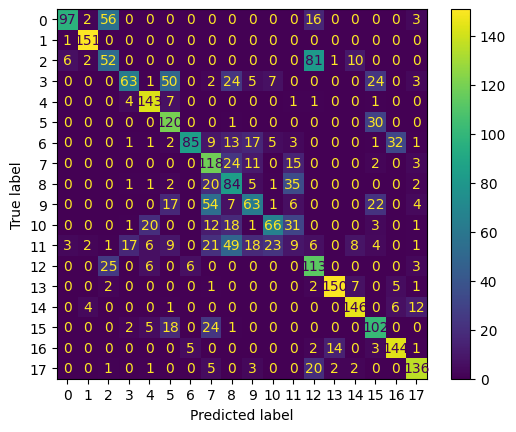

In [ ]:
disp.plot()

In [ ]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.91      0.56      0.69       174
           1       0.94      0.99      0.96       152
           2       0.38      0.34      0.36       152
           3       0.71      0.35      0.47       179
           4       0.78      0.91      0.84       157
           5       0.53      0.79      0.64       151
           6       0.89      0.50      0.64       170
           7       0.44      0.68      0.54       173
           8       0.38      0.56      0.45       151
           9       0.51      0.36      0.42       174
          10       0.64      0.43      0.52       153
          11       0.09      0.05      0.06       177
          12       0.47      0.74      0.57       153
          13       0.90      0.89      0.90       168
          14       0.84      0.86      0.85       169
          15       0.53      0.67      0.59       152
          16       0.77      0.85      0.81       169
          17       0.80    

In [ ]:
print(segments_test)

[[[ 0.9330889   0.69210684  1.1670384  ... -1.0063201   0.31541833
    1.3457334 ]
  [ 0.63128257  0.7735898   0.8815857  ... -1.0323018   0.02169292
    0.24672094]
  [ 0.38642713  0.76728725  0.76941097 ... -0.8486761   0.41055897
   -0.42698774]
  ...
  [ 0.80827415  0.9797733  -0.8794662  ...  1.0330179   0.12415083
    0.37455165]
  [ 1.0316449   0.8051026  -0.81790686 ...  0.45955804  0.46989262
    0.86454254]
  [ 1.4565611   0.40173927 -0.46223095 ... -1.6407474  -0.08311926
    1.0745913 ]]

 [[ 2.4387107   0.24417551 -0.44307914 ... -0.90740156 -0.10134884
    0.72862595]
  [ 2.0785892   0.18880306 -0.44262317 ... -0.9808628   0.5126033
   -0.4308349 ]
  [ 1.2359184   0.6520406  -0.5598138  ... -0.3972597   1.8309078
   -0.38469234]
  ...
  [ 1.1070112   0.71866757 -0.49962252 ...  0.7802884   0.14570501
    0.37915897]
  [ 1.7096009   0.66869736 -0.5538859  ...  0.8115134   0.49119228
    0.97332186]
  [ 1.4306432   1.1382375  -0.9373775  ... -0.14264984  0.23635983
    1.47

In [ ]:
print(labels_test_categorical.shape)

(1486, 18)


In [ ]:
print(labels_test_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

47/47 [==============================] - 11s 212ms/step - loss: 1.4877 - accuracy: 0.6292


In [ ]:
predictions_test = best_model.predict(segments_test)

47/47 [==============================] - 10s 195ms/step


In [ ]:
print(predictions_test)

[[9.6594632e-01 9.0294645e-07 1.6789736e-02 ... 7.0081491e-10
  1.0913213e-07 2.4816305e-07]
 [9.7198236e-01 1.7949221e-06 1.9763703e-02 ... 3.6501022e-09
  7.0336668e-08 3.9800238e-07]
 [9.7473687e-01 1.1139489e-06 1.6765373e-02 ... 8.5441310e-10
  8.5482313e-08 1.9286125e-07]
 ...
 [2.1107187e-03 1.4506668e-03 5.0707616e-02 ... 1.3387098e-02
  1.9153515e-03 6.6177976e-01]
 [3.2151642e-03 5.4023787e-03 1.3101412e-01 ... 1.5561971e-02
  1.6049951e-02 4.8163623e-01]
 [2.0650912e-03 8.0805914e-03 1.4588772e-01 ... 3.4816640e-03
  1.6539441e-02 6.4652562e-01]]


In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

[ 0  0  0 ... 17 17 17]


In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

[ 0  0  0 ... 17 17 17]


In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

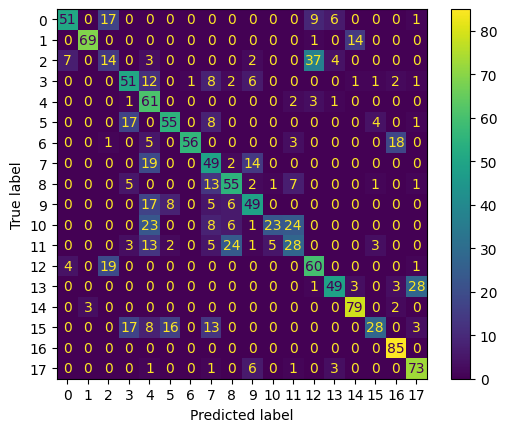

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

              precision    recall  f1-score   support

           0       0.82      0.61      0.70        84
           1       0.96      0.82      0.88        84
           2       0.27      0.21      0.24        67
           3       0.54      0.60      0.57        85
           4       0.38      0.90      0.53        68
           5       0.68      0.65      0.66        85
           6       0.98      0.67      0.80        83
           7       0.45      0.58      0.51        84
           8       0.58      0.65      0.61        85
           9       0.60      0.58      0.59        85
          10       0.79      0.27      0.40        85
          11       0.43      0.33      0.38        84
          12       0.54      0.71      0.62        84
          13       0.78      0.58      0.67        84
          14       0.81      0.94      0.87        84
          15       0.76      0.33      0.46        85
          16       0.77      1.00      0.87        85
          17       0.67    

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved")